# 02 - Unsupervised clustering with E-Means (k = 3)

**Goal:** see how far *label-free* clustering gets on this problem, using the **official Faiss E-Means** implementation, and contrast it with the supervised models of notebooks 03-05.

**What is E-Means?** A mini-batch variant of k-means from Meta FAIR (paper: *E-Means: Scaling Laws for Mini-Batch K-Means*, arXiv 2611.09501). Instead of rebuilding every centroid from the whole dataset each pass (Lloyd's algorithm), it updates centroids from mini-batches with an **exponential moving average**, revives dead clusters and sets its hyper-parameters automatically. It is a k-means *family* algorithm, but it is **not** scikit-learn's `KMeans`.

## 1. Setup and verification of the E-Means API
Before using it we check what is actually installed rather than assuming an API.

In [1]:
import sys, warnings, json
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")          # shared helpers live in src/common.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from common import (ROOT, ART, SEED, CLASSES, MAGS, COLORS, ID_COLS, SKY_COLS, FEATURE_SETS, PALETTE,
                    load_raw, clean, add_color_indices, make_splits, mlflow_experiment)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

import inspect, time, joblib, faiss
from faiss.contrib.e_means import NumpyEmeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
OUT = ART / "emeans"; OUT.mkdir(parents=True, exist_ok=True)

print("Faiss version:", faiss.__version__)
print("E-Means class:", NumpyEmeans.__module__ + "." + NumpyEmeans.__name__)
print("signature   :", inspect.signature(NumpyEmeans.__init__))
print("\n--- docstring (first lines) ---")
print("\n".join(inspect.getdoc(NumpyEmeans).splitlines()[:6]))

Faiss version: 1.16.0
E-Means class: faiss.contrib.e_means.e_means.NumpyEmeans
signature   : (self, d, k, nepochs=5, batch_size=None, alpha0=None, batch_law='auto', seed=1234, verbose=False, assignment_chunk_size=None, capture_assignments=True, spherical=False, *, unused_threshold=None, max_points_per_centroid=None)

--- docstring (first lines) ---
FP32 NumPy E-means with exact Faiss assignment.

Implements Algorithm 1 of "E-Means: Scaling Laws for Mini-Batch K-Means":
https://arxiv.org/abs/2611.09501

``nepochs`` is the epoch budget T and ``batch_size`` is B. ``alpha0`` is


**Verified API:** `NumpyEmeans(d, k, nepochs=5, ...)`; `train(x)` returns `(centroids, last_pass_labels)`; `assign(x)` assigns rows to the final centroids. This is the reference implementation shipped in `faiss.contrib.e_means` (Faiss >= 1.16). No other clustering algorithm is substituted anywhere in this project.

## 2. Data and scaling (no leakage)
Distance-based clustering is dominated by whichever feature has the largest numeric range, so the features must be scaled. The `StandardScaler` is **fitted on the training split only** and then applied to validation and test.

In [2]:
df, _ = clean(load_raw())
splits = make_splits(df)                         # same stratified 70/15/15 split as every other notebook
feats = FEATURE_SETS["with_redshift"]

scaler = StandardScaler().fit(splits["train"][feats])
X = {s: scaler.transform(splits[s][feats]).astype("float32") for s in splits}
y = {s: splits[s]["y"].values for s in splits}
print({s: x.shape for s, x in X.items()})
display(pd.DataFrame(X["train"], columns=feats).describe().loc[["mean", "std"]].round(3))

{'train': (69999, 10), 'val': (15000, 10), 'test': (15000, 10)}


,u,g,r,i,z,u-g,g-r,r-i,i-z,redshift
mean,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 3. Fit E-Means with k = 3 (primary experiment)
Three clusters because there are three astronomical classes - but note the algorithm **never sees the labels**.

In [3]:
NEPOCHS, K = 10, 3

def fit_emeans(x, k, nepochs=NEPOCHS, seed=SEED):
    model = NumpyEmeans(x.shape[1], k, nepochs=nepochs, seed=seed)
    t = time.time(); centroids, labels = model.train(x)
    return model, np.asarray(centroids, dtype="float32"), np.asarray(labels), time.time() - t

def assign(centroids, x):
    """Nearest-centroid assignment with a Faiss flat index (used for validation/test rows)."""
    index = faiss.IndexFlatL2(centroids.shape[1]); index.add(centroids)
    return index.search(np.ascontiguousarray(x, dtype="float32"), 1)[1].ravel()

model, centroids, _, train_secs = fit_emeans(X["train"], K)
labels = {s: assign(centroids, X[s]) for s in X}
print(f"trained in {train_secs:.2f}s | recipe chosen automatically:", {k: v for k, v in model.recipe.items() if k in ("batch_size", "alpha0", "batch_law", "nepochs")})
display(pd.DataFrame({s: pd.Series(l).value_counts().sort_index() for s, l in labels.items()}).rename_axis("cluster size"))

trained in 0.26s | recipe chosen automatically: {'batch_law': 'quality', 'batch_size': 512, 'alpha0': 0.7079205800507424, 'nepochs': 10}


,train,val,test
cluster size,,,
0,21790,4617,4681
1,27813,6101,5992
2,20396,4282,4327


## 4. Evaluation: four metrics
| Metric | Type | Meaning | Better |
|---|---|---|---|
| **Silhouette** | internal | how much closer a point is to its own cluster than to the next one (-1..1) | higher |
| **Davies-Bouldin** | internal | average similarity between each cluster and its most similar one | lower |
| **ARI** (Adjusted Rand Index) | external | agreement with the true classes, corrected for chance (0 = random, 1 = identical) | higher |
| **NMI** (Normalised Mutual Information) | external | information shared between clusters and true classes (0..1) | higher |

The two *internal* metrics judge cluster geometry without labels; ARI and NMI use the true labels **only for evaluation**, never for fitting. Silhouette is computed on a random 10,000-row sample because it is O(n^2).

In [4]:
def scores(x, lab, yy, n=10000, seed=SEED):
    idx = np.random.RandomState(seed).choice(len(x), min(n, len(x)), replace=False)
    return {"silhouette": silhouette_score(x[idx], lab[idx]), "davies_bouldin": davies_bouldin_score(x, lab),
            "ARI": adjusted_rand_score(yy, lab), "NMI": normalized_mutual_info_score(yy, lab)}

metrics = {s: scores(X[s], labels[s], y[s]) for s in X}
display(pd.DataFrame(metrics).T.round(4))

,silhouette,davies_bouldin,ARI,NMI
train,0.3893,1.0872,0.2314,0.2399
val,0.3896,1.0764,0.2388,0.2438
test,0.3912,1.0816,0.2369,0.2457


**Reading:** a Silhouette near 0.39 means moderately compact, moderately separated clusters; but **ARI ~0.24 and NMI ~0.25 are low** - the clusters agree only weakly with the real classes. The next cells show why.

## 5. What do the clusters contain? (sizes, composition, projection)

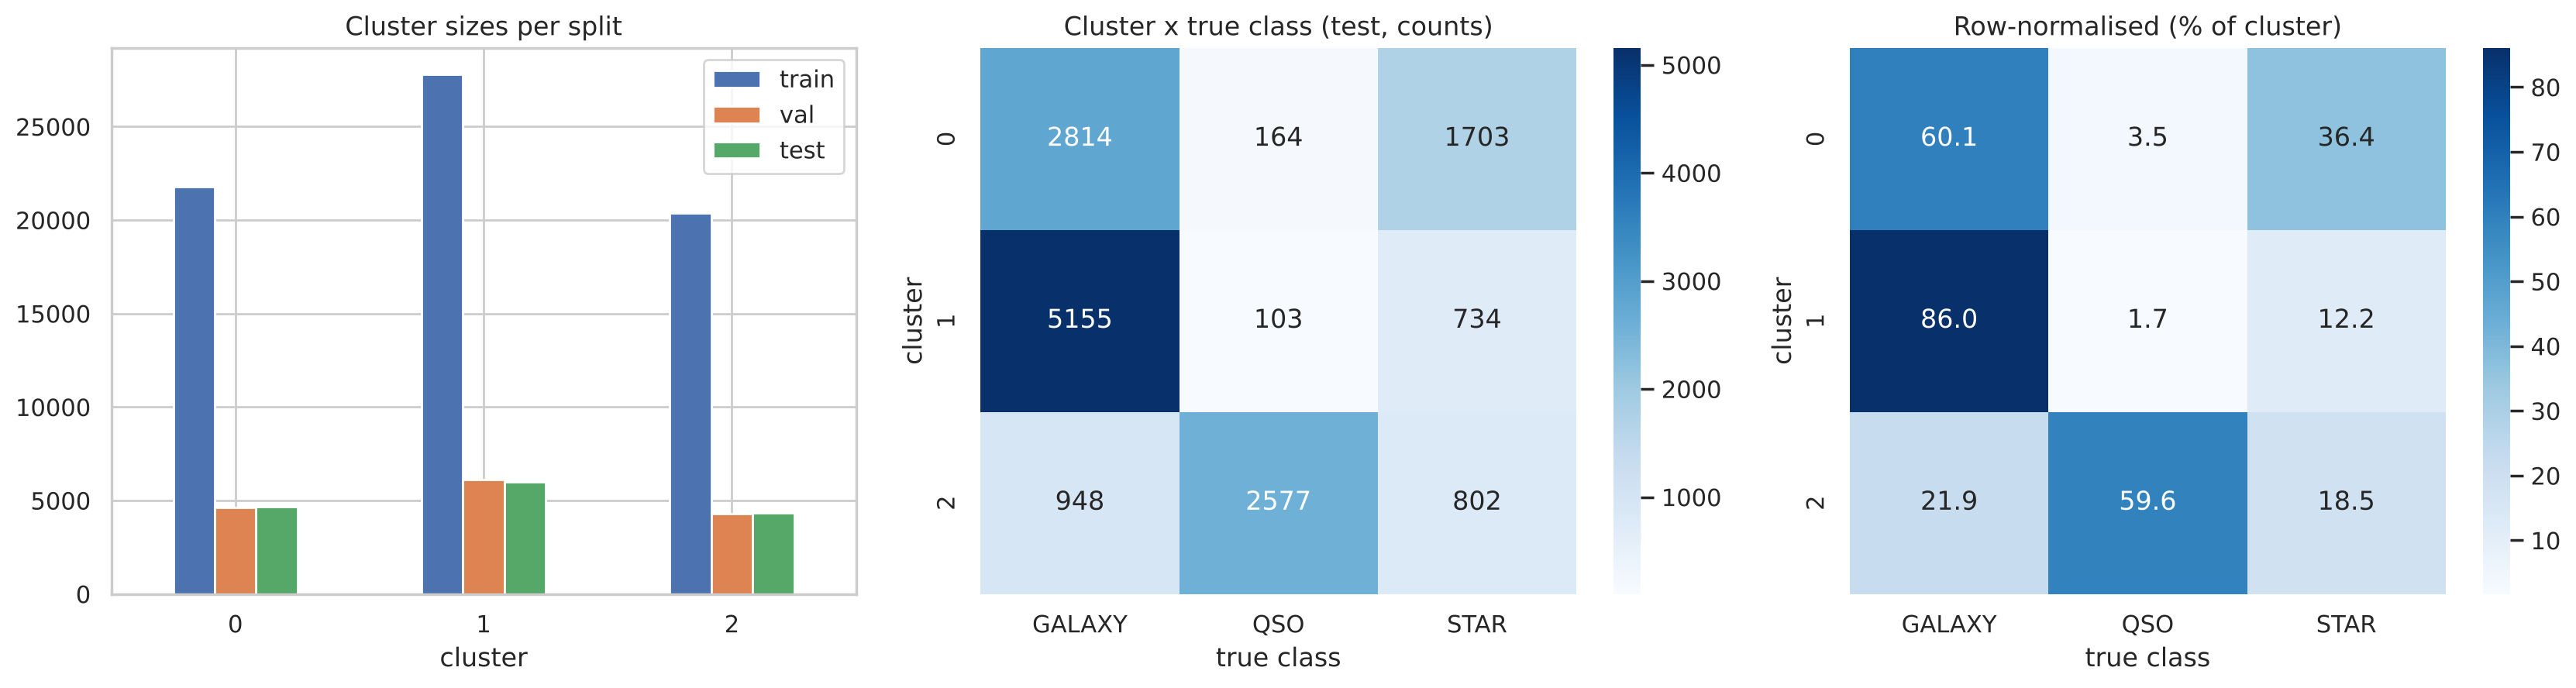

Centroids in original units:


,u,g,r,i,z,u-g,g-r,r-i,i-z,redshift
cluster,,,,,,,,,,
0,19.670000,18.103001,17.327000,16.976999,16.750000,1.567,0.776,0.350,0.228,0.105
1,24.020000,22.143999,20.502001,19.530001,19.003000,1.876,1.641,0.972,0.527,0.481
2,21.988001,21.261000,20.958000,20.731001,20.615999,0.728,0.303,0.226,0.116,1.209


In [5]:
comp = pd.crosstab(pd.Series(labels["test"], name="cluster"), pd.Series([CLASSES[i] for i in y["test"]], name="true class"))
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100
comp.to_csv(OUT / "cluster_vs_class_counts_test.csv")
sizes = {s: pd.Series(labels[s]).value_counts().sort_index().to_dict() for s in labels}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
pd.DataFrame(sizes).plot.bar(ax=ax[0])
ax[0].set_title("Cluster sizes per split")
ax[0].set_xlabel("cluster")
ax[0].tick_params(axis="x", rotation=0)

sns.heatmap(comp, annot=True, fmt="d", cmap="Blues", ax=ax[1])
ax[1].set_title("Cluster x true class (test, counts)")

sns.heatmap(comp_pct, annot=True, fmt=".1f", cmap="Blues", ax=ax[2])
ax[2].set_title("Row-normalised (% of cluster)")

plt.tight_layout(); plt.savefig(OUT / "cluster_composition.png", dpi=130); plt.show()

centers = pd.DataFrame(scaler.inverse_transform(centroids), columns=feats).round(3); centers.index.name = "cluster"
centers.to_csv(OUT / "centroids_original_units.csv")
print("Centroids in original units:")
display(centers)

**Reading:** the cluster sizes are balanced (~4.7k / 6.0k / 4.3k test rows) while the classes are not (59 / 22 / 19 %), a first sign that the clusters do not mirror the classes. Cluster 1 is mostly galaxies (86 %), cluster 2 is mostly quasars (60 %, plus galaxies), but **cluster 0 mixes 60 % galaxies with 36 % stars**. The centroid table shows why: the algorithm split the data mainly along *brightness and redshift ranges*, i.e. the directions of largest variance, not along the class boundaries.

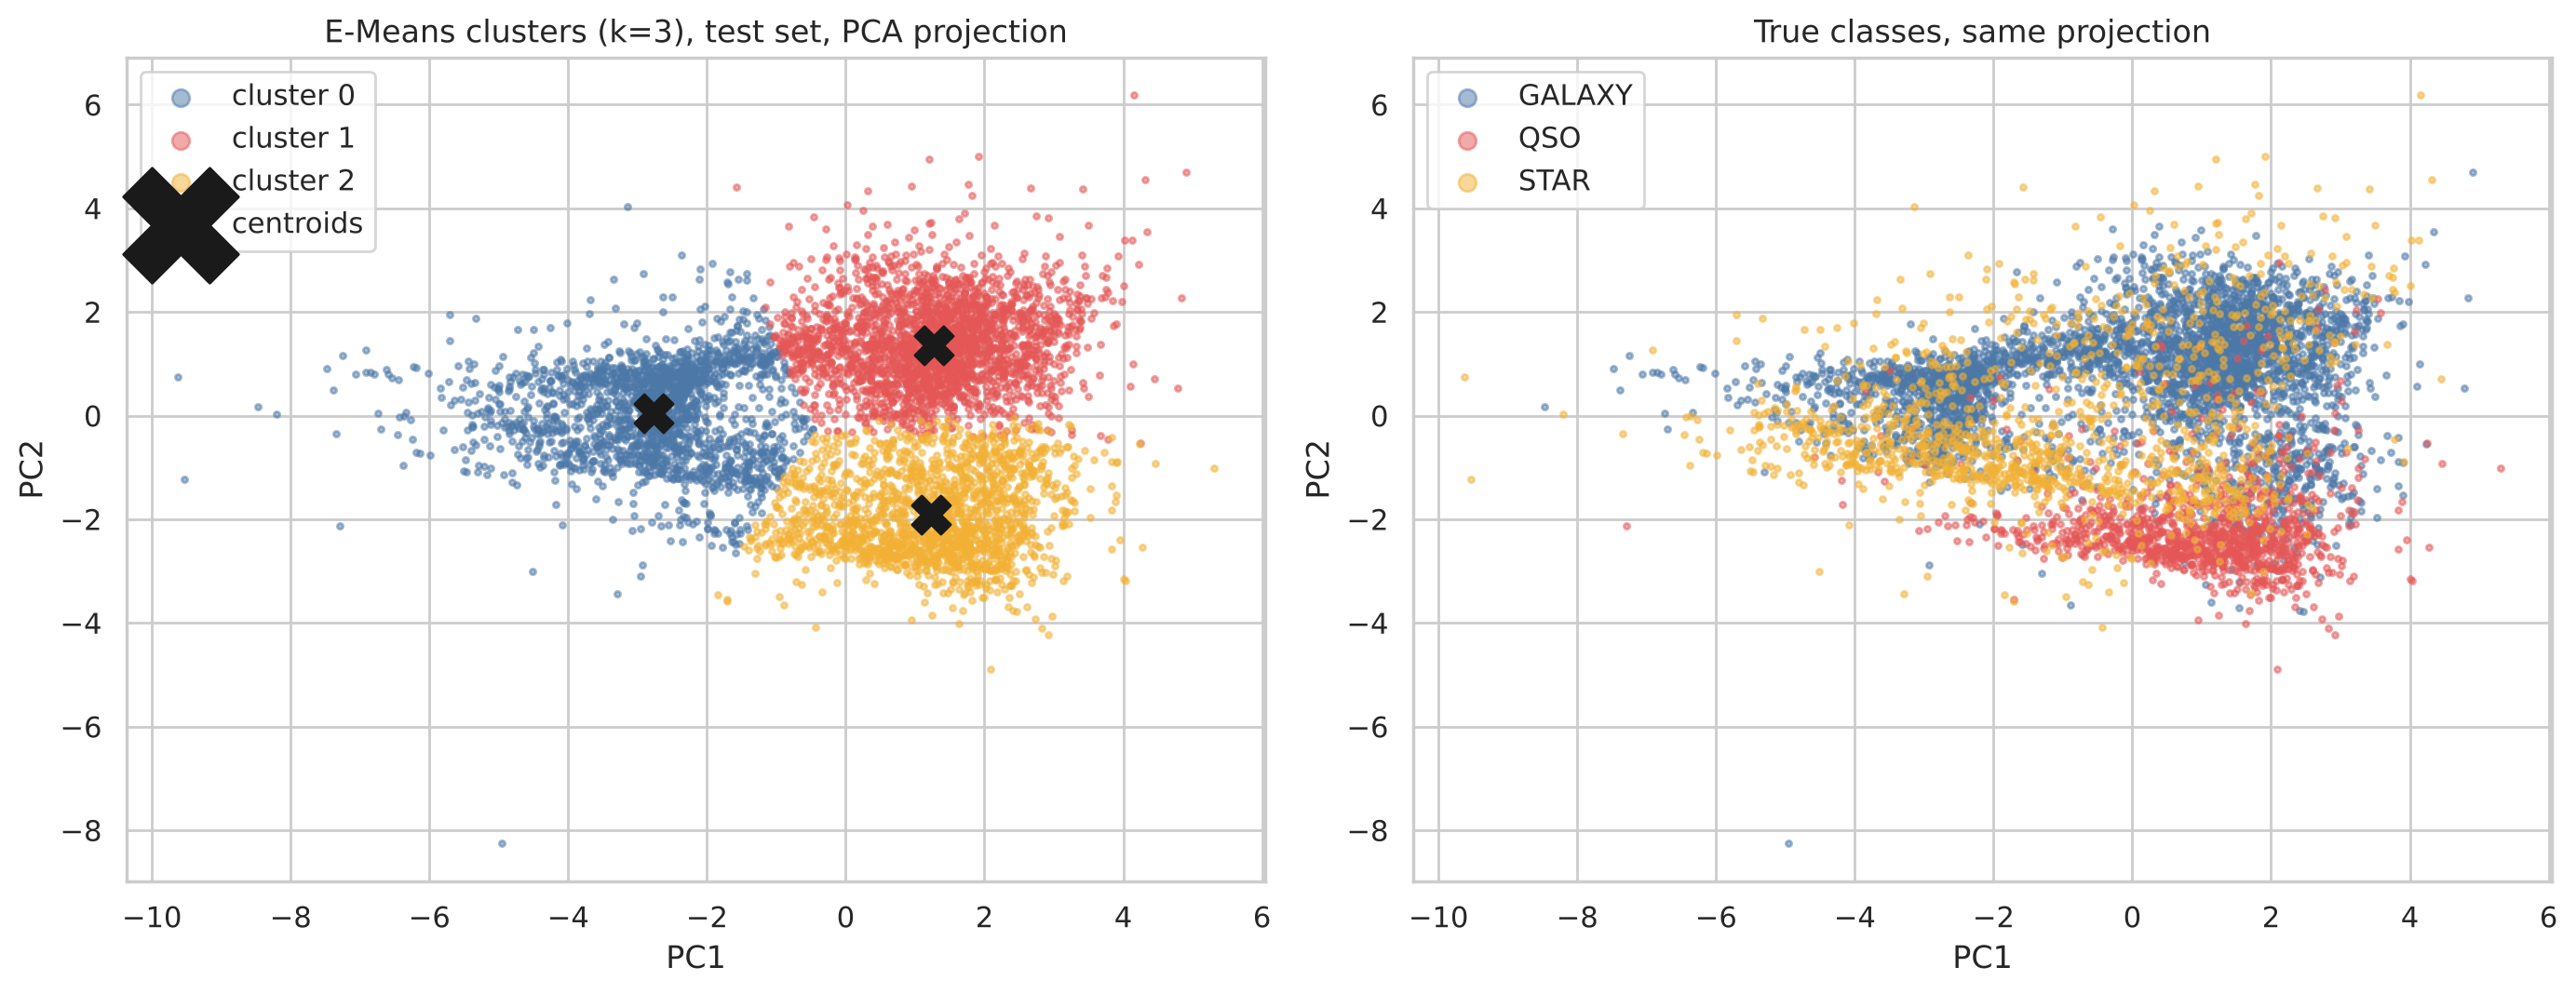

variance explained by PC1+PC2: 71.7%


In [6]:
pca = PCA(2, random_state=SEED).fit(X["train"])
Z = pca.transform(X["test"])
idx = np.random.RandomState(SEED).choice(len(Z), 6000, replace=False)
cluster_colors = ["#4c78a8", "#e45756", "#f2b134"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k in range(K):
    m = labels["test"][idx] == k
    ax[0].scatter(Z[idx][m, 0], Z[idx][m, 1], s=5, alpha=.5, color=cluster_colors[k], label=f"cluster {k}")

cen2 = pca.transform(centroids); ax[0].scatter(cen2[:, 0], cen2[:, 1], marker="X", s=220, c="k", label="centroids")
for c in range(3):
    m = y["test"][idx] == c
    ax[1].scatter(Z[idx][m, 0], Z[idx][m, 1], s=5, alpha=.5, color=PALETTE[CLASSES[c]], label=CLASSES[c])

ax[0].set_title("E-Means clusters (k=3), test set, PCA projection")
ax[1].set_title("True classes, same projection")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2"); a.legend(markerscale=3)

plt.tight_layout()
plt.savefig(OUT / "clusters_pca.png", dpi=130)
plt.show()
print("variance explained by PC1+PC2: %.1f%%" % (100 * pca.explained_variance_ratio_.sum()))

**Reading:** the left plot shows E-Means cutting the cloud into three compact regions (as k-means-type methods always do); the right plot shows the *true* classes are not three compact blobs - they are interleaved, elongated and overlapping. That mismatch is why ARI/NMI are low.

## 6. Ablation: E-Means without redshift

In [7]:
feats_nz = FEATURE_SETS["without_redshift"]
scaler_nz = StandardScaler().fit(splits["train"][feats_nz])
X_nz = {s: scaler_nz.transform(splits[s][feats_nz]).astype("float32") for s in splits}
_, C_nz, _, secs_nz = fit_emeans(X_nz["train"], K)
lab_nz = {s: assign(C_nz, X_nz[s]) for s in X_nz}
metrics_nz = {s: scores(X_nz[s], lab_nz[s], y[s]) for s in X_nz}
display(pd.concat({"with redshift": pd.DataFrame(metrics).T.loc[["test"]], "without redshift": pd.DataFrame(metrics_nz).T.loc[["test"]]}).round(4))

,,silhouette,davies_bouldin,ARI,NMI
with redshift,test,0.3912,1.0816,0.2369,0.2457
without redshift,test,0.4009,0.9972,0.2135,0.2109


**Reading:** removing redshift barely changes the clustering (internal scores even improve slightly) - because unsupervised clustering is driven by the feature *scales and variances*, not by how useful a feature is for the classes. A supervised model, in contrast, reacts strongly to redshift (notebook 05). That is a concrete illustration of the difference between the two paradigms.

## 7. Secondary experiment: is k = 3 a good choice?

,k,silhouette,davies_bouldin,ARI,NMI,train_seconds
0,2,0.3582,1.0292,0.0330,0.0584,0.2509
1,3,0.3892,1.0874,0.2310,0.2395,0.2544
2,4,0.3318,1.1882,0.1425,0.2196,0.2622
3,5,0.3214,1.3374,0.1691,0.2788,0.2634
4,6,0.2846,1.2558,0.1379,0.2565,0.2699
5,7,0.2867,1.2141,0.1403,0.2526,0.2826
6,8,0.2728,1.2572,0.1247,0.2449,0.2716


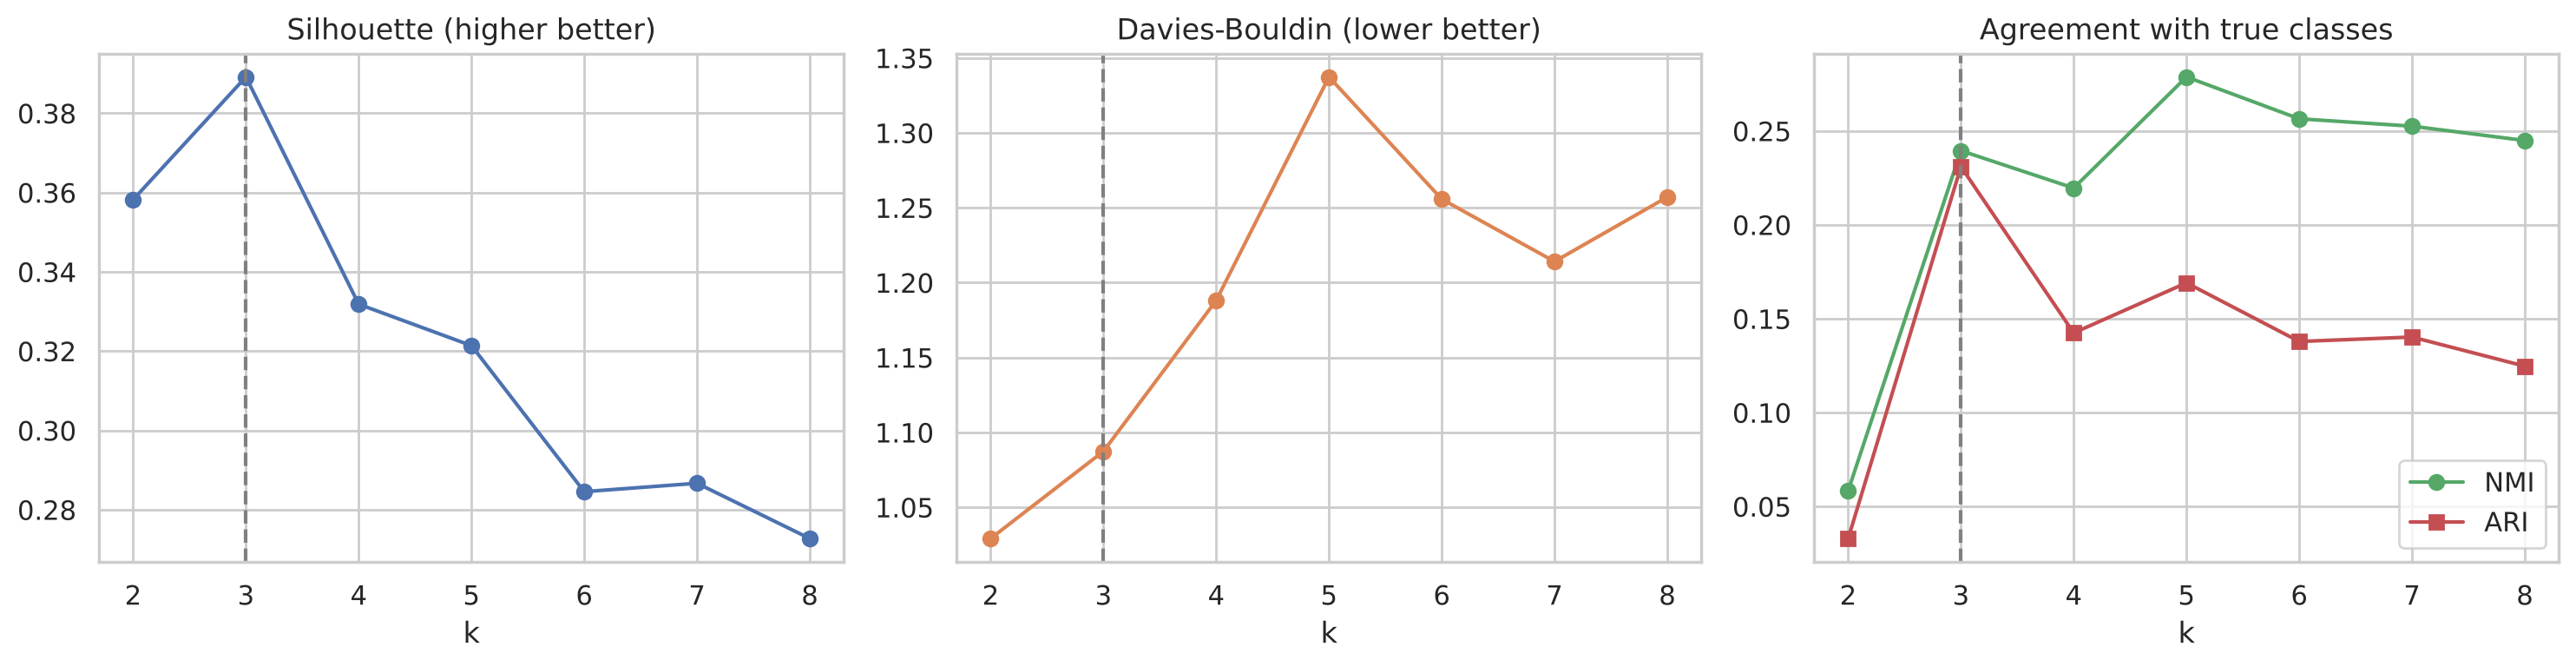

In [8]:
sweep = []
for k in range(2, 9):
    _, C, l, secs = fit_emeans(X["train"], k)
    sweep.append({"k": k, **scores(X["train"], l, y["train"]), "train_seconds": secs})

sw = pd.DataFrame(sweep)
sw.to_csv(OUT / "k_sweep.csv", index=False)
display(sw.round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(sw.k, sw.silhouette, "o-"); ax[0].set_title("Silhouette (higher better)")
ax[1].plot(sw.k, sw.davies_bouldin, "o-", color="C1"); ax[1].set_title("Davies-Bouldin (lower better)")
ax[2].plot(sw.k, sw.NMI, "o-", color="C2", label="NMI"); ax[2].plot(sw.k, sw.ARI, "s-", color="C3", label="ARI"); ax[2].legend(); ax[2].set_title("Agreement with true classes")

for a in ax: a.set_xlabel("k"); a.axvline(3, ls="--", color="grey")
plt.tight_layout()
plt.savefig(OUT / "k_sweep.png", dpi=130)
plt.show()

**Reading:** k = 3 has the best Silhouette among the tested values (and the ARI also peaks near it), so choosing three clusters is internally justified - not just copied from the number of classes. Larger k fragments the data further and weakens the agreement with the real classes.

## 8. Clustering vs classification
| | Unsupervised clustering (E-Means) | Supervised classification (CatBoost / LightGBM) |
|---|---|---|
| Uses labels when learning | **No** - groups points by distance in feature space | **Yes** - learns the mapping features -> class |
| Output | Cluster index with no inherent meaning (cluster "2" is not "QSO") | A class name with probabilities |
| Objective | Minimise within-cluster distance | Minimise classification loss (log-loss); we tune Macro-F1 |
| Evaluation | Internal (Silhouette, Davies-Bouldin) + external agreement (ARI, NMI) | Accuracy, F1, precision, recall, confusion matrix |
| Strength | Finds structure without labels | Optimises directly for the target; handles overlapping, non-spherical classes |
| Here | ARI ~0.24 - clusters follow variance, not classes | Macro-F1 ~0.977 (notebook 05) |

**Take-away:** the classes overlap in feature space and are only separable with learned, non-linear boundaries driven mostly by redshift - exactly what supervised boosting captures and distance-based clustering cannot.

## 9. Persist results (for the Streamlit app) and log to MLflow

In [9]:
joblib.dump(scaler, OUT / "scaler_with_redshift.joblib")
np.save(OUT / "centroids_with_redshift.npy", centroids)
recipe = {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in model.recipe.items()}
summary = {"implementation": f"faiss.contrib.e_means.NumpyEmeans (Faiss {faiss.__version__})", "k": K, "nepochs": NEPOCHS,
           "features": feats, "scaler": "StandardScaler (fit on train only)", "metrics_with_redshift": metrics,
           "metrics_without_redshift": metrics_nz, "train_seconds": train_secs, "cluster_sizes": sizes,
           "cluster_vs_class_pct_test": comp_pct.round(2).to_dict(orient="index"), "recipe": recipe}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))

mlflow_experiment("SDSS17-EMeans")
with mlflow.start_run(run_name="emeans_k3_with_redshift"):
    mlflow.set_tags({"algorithm": "E-Means", "implementation": summary["implementation"], "role": "primary"})
    mlflow.log_params({"k": K, "nepochs": NEPOCHS, "seed": SEED, "scaler": "StandardScaler", "features": ",".join(feats),
                       "fit_on": "train", **{f"recipe_{k}": v for k, v in recipe.items()}})
    for s, m in metrics.items(): mlflow.log_metrics({f"{s}_{k}": v for k, v in m.items()})
    mlflow.log_metric("train_seconds", train_secs)
    for k_, n in sizes["train"].items(): mlflow.log_metric(f"train_cluster_size_{k_}", n)
    mlflow.log_artifacts(str(OUT), artifact_path="emeans")

with mlflow.start_run(run_name="emeans_k3_without_redshift"):
    mlflow.set_tags({"algorithm": "E-Means", "role": "ablation"})
    mlflow.log_params({"k": K, "nepochs": NEPOCHS, "seed": SEED, "features": ",".join(feats_nz)})
    for s, m in metrics_nz.items(): mlflow.log_metrics({f"{s}_{k}": v for k, v in m.items()})

with mlflow.start_run(run_name="emeans_k_sweep"):
    mlflow.set_tags({"algorithm": "E-Means", "role": "k_sweep"})
    for r in sweep:
        for k_, v in r.items():
            if k_ != "k": mlflow.log_metric(f"sweep_{k_}", v, step=int(r["k"]))
    mlflow.log_artifact(str(OUT / "k_sweep.png"))
print("saved scaler/centroids/summary and logged 3 MLflow runs")

saved scaler/centroids/summary and logged 3 MLflow runs
